In [1]:
import pandas as pd

# Task 1

Step 1.Load Dataset
I load the e-commerce dataset from the Raw folder. I keep the original data in `raw` and do all cleaning on a copy called `df`, so the raw data is never changed.

In [2]:
raw = pd.read_csv(r"D:\data-science-week1-assignment\data\raw\ecommerce_customer_behavior_dataset_v2.csv")
df = raw.copy()

Step 2.Inspect Dataset Structure
Before cleaning, I check the size of the dataset, the data type of each column and a sample of rows, so I understand what I am working with.

In [3]:
print("Shape:", raw.shape)
raw.info()
raw.head()

Shape: (17049, 18)
<class 'pandas.DataFrame'>
RangeIndex: 17049 entries, 0 to 17048
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  17049 non-null  str    
 1   Customer_ID               17049 non-null  str    
 2   Date                      17049 non-null  str    
 3   Age                       17049 non-null  int64  
 4   Gender                    17049 non-null  str    
 5   City                      17049 non-null  str    
 6   Product_Category          17049 non-null  str    
 7   Unit_Price                17049 non-null  float64
 8   Quantity                  17049 non-null  int64  
 9   Discount_Amount           17049 non-null  float64
 10  Total_Amount              17049 non-null  float64
 11  Payment_Method            17049 non-null  str    
 12  Device_Type               17049 non-null  str    
 13  Session_Duration_Minutes  17049 non-null  int64  
 14

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


In [4]:
raw.describe(include="all")

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
count,17049,17049,17049,17049.000000,17049,17049,17049,17049.000000,17049.000000,17049.000000,17049.000000,17049,17049,17049.000000,17049.000000,17049,17049.000000,17049.000000
unique,17049,5000,450,NaN,3,10,8,NaN,NaN,NaN,NaN,5,3,NaN,NaN,2,NaN,NaN
top,ORD_000001-1,CUST_00016,2023-07-29,NaN,Female,Istanbul,Sports,NaN,NaN,NaN,NaN,Credit Card,Mobile,NaN,NaN,True,NaN,NaN
freq,1,10,59,NaN,8613,4402,2248,NaN,NaN,NaN,NaN,6801,9543,NaN,NaN,15039,NaN,NaN
mean,NaN,NaN,NaN,34.945745,NaN,NaN,NaN,447.901689,3.011379,69.788135,1277.438711,NaN,NaN,14.535633,9.003109,NaN,6.503607,3.899408
std,NaN,NaN,NaN,11.046855,NaN,NaN,NaN,722.319705,1.417027,240.704662,2358.436375,NaN,NaN,2.925524,2.259954,NaN,3.488787,1.128803
min,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,5.050000,1.000000,0.000000,6.210000,NaN,NaN,4.000000,1.000000,NaN,1.000000,1.000000
25%,NaN,NaN,NaN,26.000000,NaN,NaN,NaN,73.260000,2.000000,0.000000,172.970000,NaN,NaN,13.000000,7.000000,NaN,4.000000,3.000000
50%,NaN,NaN,NaN,35.000000,NaN,NaN,NaN,174.680000,3.000000,0.000000,455.850000,NaN,NaN,15.000000,9.000000,NaN,6.000000,4.000000
75%,NaN,NaN,NaN,42.000000,NaN,NaN,NaN,494.570000,4.000000,32.710000,1267.750000,NaN,NaN,17.000000,11.000000,NaN,8.000000,5.000000


Findings:
The raw dataset has 17,049 rows and 18 columns.
Every column has 17,049 non-null values.
Date is stored as text. The other columns are numeric, text or boolean.
The data covers 5,000 unique customers, 8 product categories and 10 cities.

Step 3.Classify Each column
The way a column is cleaned depends on its type. In this step I list every column, its type and its meaning.

In [5]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique_values": raw.nunique(),
    "example": df.iloc[0]
})
summary

,dtype,unique_values,example
Order_ID,str,17049,ORD_000001-1
Customer_ID,str,5000,CUST_00001
Date,str,450,2023-05-29
Age,int64,57,40
Gender,str,3,Male
City,str,10,Ankara
Product_Category,str,8,Books
Unit_Price,float64,14711,29.18
Quantity,int64,5,1
Discount_Amount,float64,5526,0.0


Step 4.Missing value report
Missing values can distort averages and totals. I count the nulls in each column and calculate the percentage missing, so I can decide whether to fill, remove or flag them.

In [6]:
missing = pd.DataFrame({
    "missing_count":df.isnull().sum(),
    "missing_pct":(df.isnull().mean()*100).round(2)
})
print(missing)
print("Total missing cells :",df.isnull().sum().sum())

                          missing_count  missing_pct
Order_ID                              0          0.0
Customer_ID                           0          0.0
Date                                  0          0.0
Age                                   0          0.0
Gender                                0          0.0
City                                  0          0.0
Product_Category                      0          0.0
Unit_Price                            0          0.0
Quantity                              0          0.0
Discount_Amount                       0          0.0
Total_Amount                          0          0.0
Payment_Method                        0          0.0
Device_Type                           0          0.0
Session_Duration_Minutes              0          0.0
Pages_Viewed                          0          0.0
Is_Returning_Customer                 0          0.0
Delivery_Time_Days                    0          0.0
Customer_Rating                       0       

In [7]:
print("Full duplicate rows:", df.duplicated().sum())
print("Repeated Order_IDs:", df["Order_ID"].duplicated().sum())
print("Customers with more than one order:", (df["Customer_ID"].value_counts() > 1).sum())

# Order_IDs look like ORD_000001-1, so check the base number too
df["Order_Base"] = df["Order_ID"].str.split("-").str[0]
print("Unique base order IDs:", df["Order_Base"].nunique())

g = df.groupby("Order_Base").agg(
    rows=("Order_ID", "count"),
    customers=("Customer_ID", "nunique"),
    dates=("Date", "nunique")
)
print(g["rows"].value_counts().sort_index())
print("Base IDs linked to more than one customer:", (g["customers"] > 1).sum())
print("Base IDs linked to more than one date:", (g["dates"] > 1).sum())


Full duplicate rows: 0
Repeated Order_IDs: 0
Customers with more than one order: 4108
Unique base order IDs: 5000
rows
1      892
2     1254
3     1009
4      575
5      445
6      299
7      192
8      141
9       99
10      94
Name: count, dtype: int64
Base IDs linked to more than one customer: 0
Base IDs linked to more than one date: 4103


Findings:
There are 0 fully duplicated rows and 0 repeated Order IDs.
Order IDs follow the format ORD_XXXXXX-N. The first part (for example ORD_000001) belongs to exactly one customer, and the number after the dash counts that customer's orders.
There are 5,000 unique customers, and 4,108 of them placed more than one order, mostly on different dates.

Decision:
These are valid repeat purchases and not accidental copies, so I removed no records.

Step 6.Fix data types
Analysis needs each column to have the correct type. The Date column was stored as text, so I convert it to a datetime type. This lets me group sales by month later. I also check that every date is valid and look at the date range.

In [8]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes

Order_ID                               str
Customer_ID                            str
Date                        datetime64[us]
Age                                  int64
Gender                                 str
City                                   str
Product_Category                       str
Unit_Price                         float64
Quantity                             int64
Discount_Amount                    float64
Total_Amount                       float64
Payment_Method                         str
Device_Type                            str
Session_Duration_Minutes             int64
Pages_Viewed                         int64
Is_Returning_Customer                 bool
Delivery_Time_Days                   int64
Customer_Rating                      int64
Order_Base                          object
dtype: object

In [9]:
print("Invalid dates:", df["Date"].isnull().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Invalid dates: 0
Date range: 2023-01-01 00:00:00 to 2024-03-25 00:00:00


Findings:
Date was stored as text in the raw file and is now a datetime column.
There are 0 invalid dates. The data runs from 2023-01-01 to 2024-03-25.
Is_Returning_Customer was already boolean and all numeric columns already had numeric types, so no other changes were needed.

Note: 
March 2024 ends on the 25th, so it is an incomplete month. I will keep this in mind when I compare monthly sales.




Step 7.Check ID format
IDs must follow a consistent format. A mistyped or damaged ID could break customer counts or joins later. I use a pattern check (regular expression) on Order_ID and Customer_ID, and then list any rows that fail.

In [10]:
print(df["Order_ID"].str.match(r"^ORD_\d+-\d+$").all())
print(df["Customer_ID"].str.match(r"^CUST_\d+$").all())

True
True


In [11]:
bad = df[~df["Order_ID"].str.match(r"^ORD_\d+-\d+$")]
print(len(bad))
bad.head()

0


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Order_Base


Findings:
- Both checks returned True. All 17,049 Order IDs match ORD_XXXXXX-N and all Customer IDs match CUST_XXXXX.
- The list of non-matching rows has 0 rows.

Decision: No ID needed correction.

Step 8.Validation check
Values can be present and still be logically wrong. Each rule below tests one business expectation, and the table shows how many rows break it.

In [12]:
checks = {
    "Quantity <= 0": df["Quantity"] <= 0,
    "Unit_Price <= 0": df["Unit_Price"] <= 0,
    "Negative Discount_Amount": df["Discount_Amount"] < 0,
    "Discount > Unit_Price x Quantity": df["Discount_Amount"] > df["Unit_Price"] * df["Quantity"],
    "Total_Amount mismatch": (df["Unit_Price"] * df["Quantity"] - df["Discount_Amount"] - df["Total_Amount"]).abs() > 0.01,
    "Age outside 15-100": ~df["Age"].between(15, 100),
    "Rating outside 1-5": ~df["Customer_Rating"].between(1, 5),
    "Delivery_Time_Days < 0": df["Delivery_Time_Days"] < 0,
    "Session_Duration_Minutes <= 0": df["Session_Duration_Minutes"] <= 0,
    "Pages_Viewed <= 0": df["Pages_Viewed"] <= 0,
    "Invalid or missing Date": df["Date"].isnull(),
}

report = pd.DataFrame({
    "rows_failed": {k: int(v.sum()) for k, v in checks.items()},
})
report["pct_failed"] = (report["rows_failed"] / len(df) * 100).round(2)
report["action"] = "None needed"
report

,rows_failed,pct_failed,action
Quantity <= 0,0,0.0,None needed
Unit_Price <= 0,0,0.0,None needed
Negative Discount_Amount,0,0.0,None needed
Discount > Unit_Price x Quantity,0,0.0,None needed
Total_Amount mismatch,0,0.0,None needed
Age outside 15-100,0,0.0,None needed
Rating outside 1-5,0,0.0,None needed
Delivery_Time_Days < 0,0,0.0,None needed
Session_Duration_Minutes <= 0,0,0.0,None needed
Pages_Viewed <= 0,0,0.0,None needed


Findings: 
Eleven rules were tested on all 17,049 rows and none were violated (0.00%). Total_Amount matched Unit_Price × Quantity − Discount_Amount within a 0.01 tolerance on every row.
Decision: 
No corrections were needed.

Step 9.Standardize categories
Inconsistent spellings, extra spaces or mixed case would split one group into several. Whitespace is trimmed and the unique values of each categorical column are reviewed.

In [13]:
for col in ["Gender", "City", "Product_Category", "Payment_Method", "Device_Type"]:
    before = df[col].nunique()
    df[col] = df[col].str.strip()
    after = df[col].nunique()
    print(f"{col}: {before} -> {after}")

Gender: 3 -> 3
City: 10 -> 10
Product_Category: 8 -> 8
Payment_Method: 5 -> 5
Device_Type: 3 -> 3


Findings: 
Spaces were trimmed in all five categorical columns. The unique counts did not change (Gender 3, City 10, Product_Category 8, Payment_Method 5, Device_Type 3), so no spelling or case variants existed.
Decision: 
No values needed to be changed.

Step 10.Outlier review
Total_Amount ranges from about 6 to 37,852, so I check which orders are unusually large using the IQR rule (values above Q3 + 1.5 × IQR).

In [14]:
q1, q3 = df["Total_Amount"].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
out = df[df["Total_Amount"] > upper]
print(len(out), round(len(out) / len(df) * 100, 2), "%")
print(out["Product_Category"].value_counts())

1943 11.4 %
Product_Category
Electronics      1215
Home & Garden     435
Sports            254
Fashion            37
Toys                2
Name: count, dtype: int64


Findings: 
1,943 orders (11.4%) were flagged. Most are in Electronics (1,215), Home & Garden (435) and Sports (254), which are higher-priced categories. The Step 8 check confirmed every amount is arithmetically correct.
Decision: 
These are valid high-value orders, so I kept all of them. I will use the median alongside the average in later analysis because the data is right-skewed.

In [15]:
df["Order_Month"] = df["Date"].dt.to_period("M").astype(str)
df["Delivery_Status"] = pd.cut(df["Delivery_Time_Days"], [-1, 3, 7, 999],
                               labels=["Fast", "Standard", "Slow"])

In [16]:
df[["Date", "Order_Month", "Delivery_Time_Days", "Delivery_Status"]].head()

,Date,Order_Month,Delivery_Time_Days,Delivery_Status
0,2023-05-29,2023-05,13,Slow
1,2023-10-12,2023-10,6,Standard
2,2023-12-05,2023-12,9,Slow
3,2023-05-11,2023-05,4,Standard
4,2023-06-16,2023-06,6,Standard


In [17]:
df["Delivery_Status"].value_counts()

Delivery_Status
Standard    8221
Slow        5496
Fast        3332
Name: count, dtype: int64

Findings:
Three columns were added: Order_Base, Order_Month and Delivery_Status.
Delivery_Status: Fast (3 days or fewer) has 3,332 orders, Standard (4 to 7 days) has 8,221 and Slow (8 days or more) has 5,496. Together they cover all 17,049 rows.

Assumption: 
The dataset has no delivery status field. The 3-day and 7-day cut-offs are my own choice for analysis and are not part of the original data.

Step 12: Saving the Cleaned Dataset

The raw file stays unchanged. The cleaned data is saved as a separate file in the cleaned folder, and I compare it with the raw data to confirm that no rows were lost.

In [18]:
clean_path = r"D:\data-science-week1-assignment\data\cleaned\cleaned_data.csv"

df.to_csv(clean_path, index=False)

print("Raw rows:", len(raw))
print("Cleaned rows:", len(df))
print("Rows retained %:", round(len(df) / len(raw) * 100, 2))
print("Columns:", raw.shape[1], "->", df.shape[1])

check = pd.read_csv(clean_path)
print("Saved file shape:", check.shape)

Raw rows: 17049
Cleaned rows: 17049
Rows retained %: 100.0
Columns: 18 -> 21
Saved file shape: (17049, 21)


Findings: The cleaned file was saved separately and the raw file was not changed. All 17,049 rows were retained (100%). Columns went from 18 to 21 because of three derived columns: Order_Base, Order_Month and Delivery_Status.

# Task 2: Sales Data Analysis
Calculate core KPIs, find sales trends and generate customer insights from the cleaned dataset.

In [19]:
df = pd.read_csv(r"D:\data-science-week1-assignment\data\cleaned\cleaned_data.csv", parse_dates=["Date"])
print(df.shape)

(17049, 21)


In [20]:
df.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,...,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Order_Base,Order_Month,Delivery_Status
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,...,Digital Wallet,Mobile,14,9,True,13,4,ORD_000001,2023-05,Slow
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,...,Credit Card,Desktop,14,8,True,6,2,ORD_000001,2023-10,Standard
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,...,Credit Card,Mobile,15,10,True,9,4,ORD_000001,2023-12,Slow
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,...,Digital Wallet,Desktop,16,13,True,4,4,ORD_000002,2023-05,Standard
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,...,Credit Card,Mobile,14,7,True,6,4,ORD_000002,2023-06,Standard


Step 1: Core KPIs
KPIs (key performance indicators) summarise business performance in a few numbers. I calculate total revenue, total orders, average order value, total units sold, and the top category by revenue and by units.

Assumptions:
Every row is treated as a completed sale, because the dataset has no cancelled or returned status.
Revenue means Total_Amount, which is the final amount paid after discount.
The dataset has no product name, so Product_Category stands in for "product".

In [21]:
total_revenue = df["Total_Amount"].sum()
total_orders = len(df)
aov = total_revenue / total_orders
median_order = df["Total_Amount"].median()
units_sold = df["Quantity"].sum()

cat_rev = df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
cat_units = df.groupby("Product_Category")["Quantity"].sum().sort_values(ascending=False)

kpi = pd.DataFrame({
    "KPI": ["Total Revenue", "Total Orders", "Average Order Value", "Median Order Value",
            "Total Units Sold", "Top Category (revenue)", "Top Category (units)"],
    "Meaning": [
        "Total value of all sales (sum of Total_Amount)",
        "Number of order records",
        "Total revenue divided by total orders",
        "Middle order value, less affected by very large orders",
        "Sum of Quantity across all orders",
        "Category with the highest revenue",
        "Category with the most units sold",
    ],
    "Value": [round(total_revenue, 2), total_orders, round(aov, 2), round(median_order, 2),
              units_sold, cat_rev.index[0], cat_units.index[0]],
})
kpi.set_index("KPI")

,Meaning,Value
KPI,,
Total Revenue,Total value of all sales (sum of Total_Amount),21779052.59
Total Orders,Number of order records,17049
Average Order Value,Total revenue divided by total orders,1277.44
Median Order Value,"Middle order value, less affected by very larg...",455.85
Total Units Sold,Sum of Quantity across all orders,51341
Top Category (revenue),Category with the highest revenue,Electronics
Top Category (units),Category with the most units sold,Sports


In [22]:
# Rebuild revenue from its parts and compare with Total_Amount
rebuilt = (df["Unit_Price"] * df["Quantity"] - df["Discount_Amount"]).sum()
print("Revenue from Total_Amount:", round(total_revenue, 2))
print("Revenue rebuilt from price, quantity, discount:", round(rebuilt, 2))

# Category revenue should add back up to total revenue
print("Category revenue adds up:", round(cat_rev.sum(), 2) == round(total_revenue, 2))
print("Category units add up:", cat_units.sum() == units_sold)

Revenue from Total_Amount: 21779052.59
Revenue rebuilt from price, quantity, discount: 21779052.59
Category revenue adds up: True
Category units add up: True


Observations:
The 17,049 orders generated a total revenue of about 21.78 million, with 51,341 units sold.
The average order value (1,277.44) is about 2.8 times the median (455.85). A small number of very large orders pull the average up, so the median is a better description of a typical order.
Electronics leads in revenue, but Sports sells the most units. A category can sell the most items without earning the most money, because Electronics has much higher prices.

Check: 
Revenue rebuilt from price, quantity and discount matched Total_Amount, and the category totals add back up to the overall totals.

Step 2: Category performance
The KPI table named only the top category. This step ranks all 8 categories, so you can explain why Electronics leads in revenue and Sports in units.

In [23]:
cat = df.groupby("Product_Category").agg(
    revenue=("Total_Amount", "sum"),
    orders=("Order_ID", "count"),
    units=("Quantity", "sum"),
    avg_order_value=("Total_Amount", "mean"),
).sort_values("revenue", ascending=False)

cat["revenue_share_pct"] = (cat["revenue"] / cat["revenue"].sum() * 100).round(2)
cat["revenue"] = cat["revenue"].round(2)
cat["avg_order_value"] = cat["avg_order_value"].round(2)
cat

,revenue,orders,units,avg_order_value,revenue_share_pct
Product_Category,,,,,
Electronics,10481897.65,2074,6277,5053.95,48.13
Home & Garden,4023903.94,2060,6155,1953.35,18.48
Sports,3205086.99,2248,6856,1425.75,14.72
Fashion,1577035.70,2056,6078,767.04,7.24
Toys,1014237.53,2090,6303,485.28,4.66
Beauty,694437.02,2212,6564,313.94,3.19
Food,422054.65,2103,6381,200.69,1.94
Books,360399.11,2206,6727,163.37,1.65


In [24]:
#Check Cell
print("Revenue shares add up to:", cat["revenue_share_pct"].sum().round(1))
print("Orders add up:", cat["orders"].sum() == len(df))

Revenue shares add up to: 100.0
Orders add up: True


Observations:
Electronics generates 48.13% of total revenue from only about 12% of orders. Together with Home & Garden and Sports, the top three categories account for about 81% of revenue.
Order counts are spread fairly evenly across the eight categories (2,056 to 2,248 orders each), so the large revenue differences come from price, not demand. Electronics' average order value (5,053.95) is about 31 times that of Books (163.37).
Sports has the most orders (2,248) and units (6,856), but is third in revenue (14.72%). Selling many items does not mean earning the most money.
Beauty, Food and Books together contribute under 7% of revenue.

Check:
Revenue shares add up to 100% and category orders add up to the 17,049 total orders.

Step 3: Monthly Sales Trend
see how revenue and orders change over time. The handbook requires at least one trend interpretation that explains why the change matters to the business.


I group the data by month to see how revenue, orders and average order value change over time, and I calculate the month-on-month change in revenue. The data ends on 25 March 2024, so March 2024 is an incomplete month and has to be read with care.

In [25]:
monthly = df.groupby("Order_Month").agg(
    revenue=("Total_Amount", "sum"),
    orders=("Order_ID", "count"),
    avg_order_value=("Total_Amount", "mean"),
)
monthly["revenue_change_pct"] = (monthly["revenue"].pct_change() * 100).round(1)
monthly["revenue"] = monthly["revenue"].round(2)
monthly["avg_order_value"] = monthly["avg_order_value"].round(2)
monthly

,revenue,orders,avg_order_value,revenue_change_pct
Order_Month,,,,
2023-01,1311603.21,1145,1145.50,NaN
2023-02,1409777.29,1078,1307.77,7.5
2023-03,1458005.58,1085,1343.78,3.4
2023-04,1499648.03,1142,1313.18,2.9
2023-05,1483511.61,1214,1222.00,-1.1
2023-06,1380984.94,1088,1269.29,-6.9
2023-07,1560046.14,1195,1305.48,13.0
2023-08,1510999.75,1178,1282.68,-3.1
2023-09,1502164.37,1134,1324.66,-0.6


In [26]:
#Check cell
print("Months:", len(monthly))
print("Monthly revenue adds up to total:", round(monthly["revenue"].sum(), 2) == round(total_revenue, 2))
print("Monthly orders add up:", monthly["orders"].sum() == len(df))

Months: 15
Monthly revenue adds up to total: True
Monthly orders add up: True


Observations:
Monthly revenue stays between about 1.27 million and 1.59 million, with no steady upward or downward trend over the 15 months.
July 2023 rose 13.0% over June (1,560,046), and December 2023 was the highest month (1,586,214, up 9.7%). June 2023 (-6.9%) and November 2023 (-5.9%) were the main dips.
Changes in revenue follow the number of orders more than order size. The average order value stays between 1,145 and 1,344 in every month. For example, the 10.8% revenue fall in February 2024 came with a 13.0% fall in orders, while the average order value rose.
March 2024 has data only up to the 25th, so its lower total (1,272,102) is mostly a shorter period.
January and February 2024 combined are about 3.6% above the same two months in 2023.

Interpretation:
Revenue is stable rather than growing, and month-to-month swings come from changes in order volume. This matters because it suggests that sales depend on how many customers order each month, not on larger baskets. The data does not show what caused the peaks, so I do not assume a reason for them.

Check:
Monthly revenue adds up to the total revenue and monthly orders add up to 17,049.

Step 4: City Performance
I compare the ten cities by revenue, orders, average order value and share of total revenue. I also check whether high-value orders (above the Q3 + 1.5 × IQR limit from Task 1) are concentrated in particular cities.

In [27]:
city = df.groupby("City").agg(
    revenue=("Total_Amount", "sum"),
    orders=("Order_ID", "count"),
    avg_order_value=("Total_Amount", "mean"),
).sort_values("revenue", ascending=False)

city["revenue_share_pct"] = (city["revenue"] / city["revenue"].sum() * 100).round(2)
city["revenue"] = city["revenue"].round(2)
city["avg_order_value"] = city["avg_order_value"].round(2)

# High-value orders by city
q1, q3 = df["Total_Amount"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
is_high = df["Total_Amount"] > upper
city["high_value_pct"] = (is_high.groupby(df["City"]).mean() * 100).round(1)
city

,revenue,orders,avg_order_value,revenue_share_pct,high_value_pct
City,,,,,
Istanbul,5646595.78,4402,1282.73,25.93,11.9
Ankara,3052443.10,2422,1260.30,14.02,11.3
Izmir,2651743.92,2072,1279.80,12.18,11.4
Bursa,2317028.10,1721,1346.33,10.64,11.7
Antalya,1661594.15,1246,1333.54,7.63,11.2
Gaziantep,1573422.25,1183,1330.03,7.22,11.7
Adana,1512320.19,1326,1140.51,6.94,9.8
Konya,1363152.80,1120,1217.10,6.26,10.5
Kayseri,1091658.53,851,1282.79,5.01,11.8


In [28]:
#Check cell
print("Revenue shares add up to:", city["revenue_share_pct"].sum().round(1))
print("City orders add up:", city["orders"].sum() == len(df))

Revenue shares add up to: 100.0
City orders add up: True


Observations:
Istanbul generates the most revenue (5.65 million, 25.93% of the total) and has the most orders (4,402). Its share of revenue is almost the same as its share of orders (25.82%), so its lead comes from order volume, not from larger orders.
The top three cities (Istanbul, Ankara and Izmir) account for about 52% of revenue.
Average order value is similar across cities, from 1,140.51 in Adana to 1,346.33 in Bursa.
Adana has more orders than Antalya (1,326 against 1,246) but less revenue, because its average order value (1,140.51) and its share of high-value orders (9.8%) are the lowest of the ten cities.
High-value orders are spread evenly, between 9.8% and 11.9% of orders in every city, so they are not concentrated in any one city.

Check:
City revenue shares add up to 100% and city orders add up to 17,049.

Step 5: Delivery Status Analysis
I compare Fast, Standard and Slow deliveries by number of orders, revenue, average order value and average customer rating, to see whether delivery speed is linked to order value or satisfaction. Delivery_Status was derived from Delivery_Time_Days in Task 1, with cut-offs of 3 and 7 days that are my own assumption.

In [29]:
delivery = df.groupby("Delivery_Status").agg(
    orders=("Order_ID", "count"),
    revenue=("Total_Amount", "sum"),
    avg_order_value=("Total_Amount", "mean"),
    avg_rating=("Customer_Rating", "mean"),
).reindex(["Fast", "Standard", "Slow"])

delivery["order_share_pct"] = (delivery["orders"] / delivery["orders"].sum() * 100).round(1)
delivery["revenue_share_pct"] = (delivery["revenue"] / delivery["revenue"].sum() * 100).round(1)
delivery["revenue"] = delivery["revenue"].round(2)
delivery["avg_order_value"] = delivery["avg_order_value"].round(2)
delivery["avg_rating"] = delivery["avg_rating"].round(2)
delivery

,orders,revenue,avg_order_value,avg_rating,order_share_pct,revenue_share_pct
Delivery_Status,,,,,,
Fast,3332,4561252.20,1368.92,3.91,19.5,20.9
Standard,8221,10569313.68,1285.65,3.90,48.2,48.5
Slow,5496,6648486.71,1209.70,3.89,32.2,30.5


In [30]:
#Check Cell
print("Delivery orders add up:", delivery["orders"].sum() == len(df))
print("Delivery revenue adds up:", round(delivery["revenue"].sum(), 2) == round(total_revenue, 2))

Delivery orders add up: True
Delivery revenue adds up: True


Observations:
Standard deliveries (4 to 7 days) are the largest group, with 48.2% of orders and 48.5% of revenue. Slow deliveries (8 days or more) make up 32.2% of orders and 30.5% of revenue, and Fast deliveries (3 days or fewer) make up 19.5% of orders and 20.9% of revenue.
Average order value falls as delivery gets slower: 1,368.92 for Fast, 1,285.65 for Standard and 1,209.70 for Slow. Fast orders are about 13% higher than Slow orders.
Customer ratings are almost the same in every group (3.91, 3.90 and 3.89), so delivery speed does not appear to be linked to satisfaction in this data.

Interpretation: 
About one order in three takes 8 days or more to arrive, but those customers rate their experience about the same as customers who receive orders faster. This matters because it suggests that slow delivery is not reducing satisfaction scores. The data cannot show whether it affects repeat buying, and the 3-day and 7-day cut-offs are my own assumption, so the group sizes depend on those choices.

Check:
Delivery orders add up to 17,049 and delivery revenue adds up to the total revenue.

Step 6: Customer Insights
I look at customers in two ways. First, I compare orders from returning and first-time customers using the Is_Returning_Customer column. Second, I group the data by Customer_ID to see how many orders and how much revenue each of the 5,000 customers brings, and whether revenue is spread evenly or concentrated in a few customers.

In [31]:
# returning vs new customers
ret = df.groupby("Is_Returning_Customer").agg(
    orders=("Order_ID", "count"),
    revenue=("Total_Amount", "sum"),
    avg_order_value=("Total_Amount", "mean"),
)
ret["order_share_pct"] = (ret["orders"] / ret["orders"].sum() * 100).round(1)
ret["revenue_share_pct"] = (ret["revenue"] / ret["revenue"].sum() * 100).round(1)
ret["revenue"] = ret["revenue"].round(2)
ret["avg_order_value"] = ret["avg_order_value"].round(2)
ret

,orders,revenue,avg_order_value,order_share_pct,revenue_share_pct
Is_Returning_Customer,,,,,
False,2010,2588332.13,1287.73,11.8,11.9
True,15039,19190720.46,1276.06,88.2,88.1


In [32]:
# customer-level view
cust = df.groupby("Customer_ID").agg(
    orders=("Order_ID", "count"),
    revenue=("Total_Amount", "sum"),
).sort_values("revenue", ascending=False)

print("Customers:", len(cust))
print("Customers with more than one order:", (cust["orders"] > 1).sum())
print("Orders per customer (min / median / max):",
      cust["orders"].min(), cust["orders"].median(), cust["orders"].max())

top10 = cust.head(int(len(cust) * 0.10))
print("Top 10% of customers:", len(top10))
print("Their share of revenue (%):", round(top10["revenue"].sum() / cust["revenue"].sum() * 100, 1))

repeat = cust[cust["orders"] > 1]
print("Repeat customers' share of revenue (%):", round(repeat["revenue"].sum() / cust["revenue"].sum() * 100, 1))

Customers: 5000
Customers with more than one order: 4108
Orders per customer (min / median / max): 1 3.0 10
Top 10% of customers: 500
Their share of revenue (%): 38.8
Repeat customers' share of revenue (%): 95.1


In [33]:
# Check Cell
print("Customer orders add up:", cust["orders"].sum() == len(df))
print("Customer revenue adds up:", round(cust["revenue"].sum(), 2) == round(total_revenue, 2))

Customer orders add up: True
Customer revenue adds up: True


Observations:
Returning customers account for 88.2% of orders and 88.1% of revenue, according to the Is_Returning_Customer flag.
Average order value is almost the same for returning customers (1,276.06) and first-time customers (1,287.73), so returning customers matter because they order often, not because they spend more per order.
The 5,000 customers placed between 1 and 10 orders each, with a median of 3. 4,108 customers ordered more than once, and together they bring 95.1% of revenue.
Revenue is moderately concentrated: the top 10% of customers (500 customers) bring 38.8% of revenue.

Interpretation: 
Revenue depends heavily on customers who buy repeatedly. This matters because keeping existing customers buying is likely to protect more revenue than relying on first-time buyers. The two repeat-customer figures use different definitions: the first uses the Is_Returning_Customer flag on each order, and the second uses the number of orders per Customer_ID. The data does not show why the top customers spend more.

Check:
Customer orders add up to 17,049 and customer revenue adds up to the total revenue.

Key Observations (Task 2)
1. The 17,049 orders generated 21.78 million in revenue and 51,341 units. The average order value (1,277.44) is about 2.8 times the median (455.85), because a few very large orders pull the average up.
2. Electronics generates 48.13% of revenue from about 12% of orders. Electronics, Home & Garden and Sports together bring about 81% of revenue.
3. Sports has the most orders (2,248) and units (6,856) but ranks third in revenue. Order counts are similar across all eight categories, so revenue differences come from price.
4. Monthly revenue stays between about 1.27 million and 1.59 million, with no steady trend. July 2023 (+13.0%) and December 2023 (the highest month) are the peaks, and changes follow order volume more than order size. March 2024 is incomplete.
5. Istanbul brings 25.93% of revenue, in line with its 25.8% share of orders, and the top three cities bring about 52%. Average order value is similar across cities (1,140.51 to 1,346.33).
6. Delivery speed shows no link to satisfaction: average ratings are 3.91, 3.90 and 3.89 for Fast, Standard and Slow. Slow deliveries (8 days or more) are 32.2% of orders.
7. Returning customers account for 88.2% of orders and 88.1% of revenue, with an average order value similar to first-time customers.
8. The top 10% of customers bring 38.8% of revenue, and customers who ordered more than once bring 95.1%.

# Task 3: Visualization Challenge
Communicate the findings of the sales analysis with clear charts, a dashboard mockup and a short interpretation for each visual.

Step 1: Setup and Bar Chart – Revenue by Category
All charts use the tables built in Task 2. I use one colour scheme throughout: a single blue for normal bars and an orange highlight for the top category. Each chart has a title, labelled axes and is saved to the outputs folder.

In [34]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

chart_dir = "../outputs/charts"
dash_dir = "../outputs/dashboard"
os.makedirs(chart_dir, exist_ok=True)
os.makedirs(dash_dir, exist_ok=True)

BLUE = "#3B6EA5"
HIGHLIGHT = "#E8833A"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

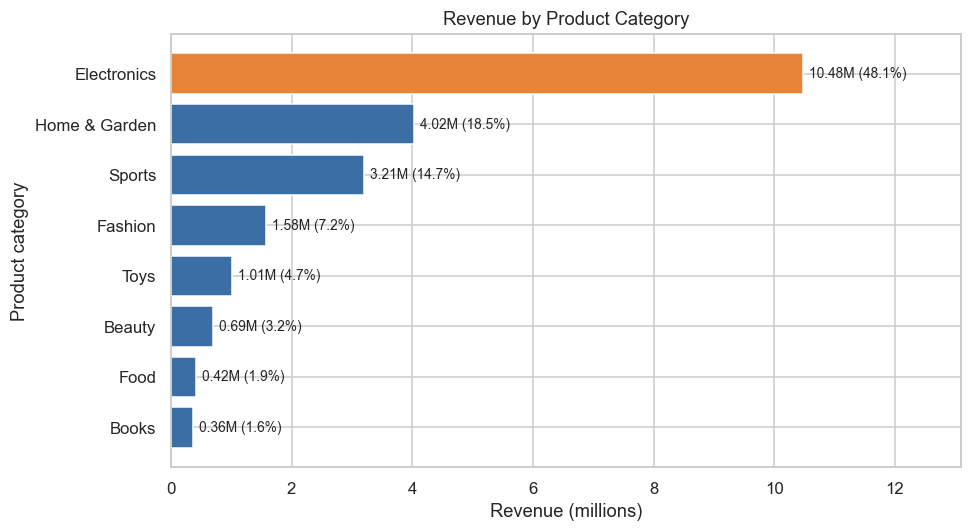

In [35]:
cat_sorted = cat.sort_values("revenue", ascending=True)   # ascending so the largest bar is at the top
colors = [HIGHLIGHT if c == cat_sorted.index[-1] else BLUE for c in cat_sorted.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cat_sorted.index, cat_sorted["revenue"] / 1e6, color=colors)

for i, (rev, share) in enumerate(zip(cat_sorted["revenue"], cat_sorted["revenue_share_pct"])):
    ax.text(rev / 1e6 + 0.1, i, f"{rev/1e6:.2f}M ({share:.1f}%)", va="center", fontsize=9)

ax.set_title("Revenue by Product Category")
ax.set_xlabel("Revenue (millions)")
ax.set_ylabel("Product category")
ax.set_xlim(0, cat_sorted["revenue"].max() / 1e6 * 1.25)
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "revenue-by-category.png"), dpi=150, bbox_inches="tight")
plt.show()

Insight: 
Electronics brings 10.48 million, 48.1% of all revenue, which is more than Home & Garden (4.02 million) and Sports (3.21 million) combined. Beauty, Food and Books together contribute under 7%. Since order counts are similar across categories, the gap reflects price per order, not demand.

Step 2: Bar Charts – Orders by City and Delivery Status
Two more category comparisons. The first shows where order volume is highest, and the second shows how many orders fall into each delivery speed group. The colour scheme stays the same, with orange marking the largest bar in each chart.

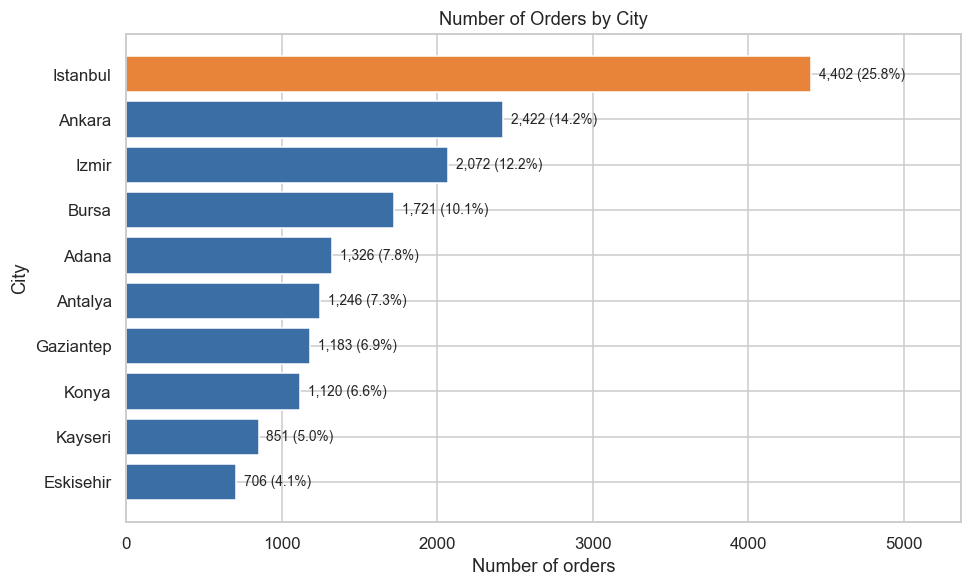

In [36]:
# orders by city
city_orders = city.sort_values("orders", ascending=True)
colors = [HIGHLIGHT if c == city_orders.index[-1] else BLUE for c in city_orders.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(city_orders.index, city_orders["orders"], color=colors)

for i, n in enumerate(city_orders["orders"]):
    ax.text(n + 50, i, f"{n:,} ({n / len(df) * 100:.1f}%)", va="center", fontsize=9)

ax.set_title("Number of Orders by City")
ax.set_xlabel("Number of orders")
ax.set_ylabel("City")
ax.set_xlim(0, city_orders["orders"].max() * 1.22)
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "orders-by-city.png"), dpi=150, bbox_inches="tight")
plt.show()

Insight: Istanbul has the most orders (4,402, 25.8% of the total), followed by Ankara (2,422) and Izmir (2,072). The top three cities together account for about 52% of all orders, and the other seven share the rest. Order volume is therefore concentrated in a few large cities.

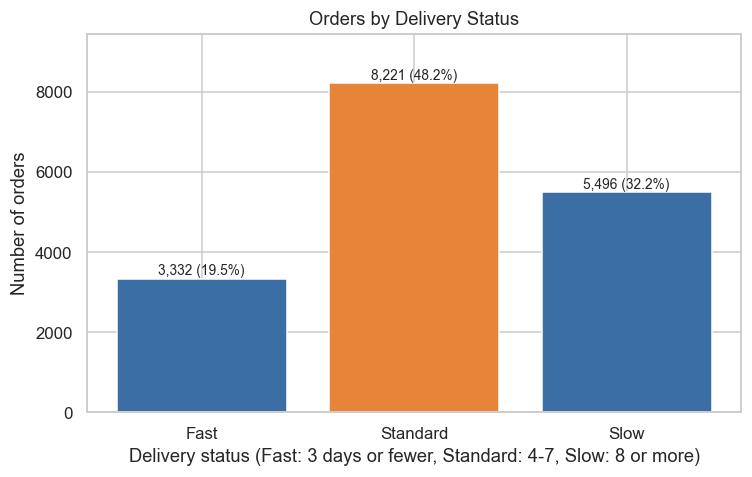

In [37]:
# delivery status counts
status = delivery["orders"]            # already ordered Fast, Standard, Slow
colors = [HIGHLIGHT if s == status.idxmax() else BLUE for s in status.index]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(status.index, status.values, color=colors)

for i, n in enumerate(status.values):
    ax.text(i, n + 100, f"{n:,} ({n / len(df) * 100:.1f}%)", ha="center", fontsize=9)

ax.set_title("Orders by Delivery Status")
ax.set_xlabel("Delivery status (Fast: 3 days or fewer, Standard: 4-7, Slow: 8 or more)")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, status.max() * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "delivery-status-counts.png"), dpi=150, bbox_inches="tight")
plt.show()

Insight: Standard deliveries (4 to 7 days) are the largest group with 8,221 orders (48.2%). Slow deliveries (8 days or more) make up 32.2% of orders, and Fast deliveries (3 days or fewer) make up 19.5%. The three groups depend on the 3-day and 7-day cut-offs, which are my own assumption.

Step 3: Line Chart – Monthly Revenue Trend
The line chart shows how revenue changes month by month. The last point (March 2024) is drawn with a dashed line and a hollow marker because the data ends on 25 March, so it is not a full month. The biggest rise, the peak and the biggest drop are annotated.

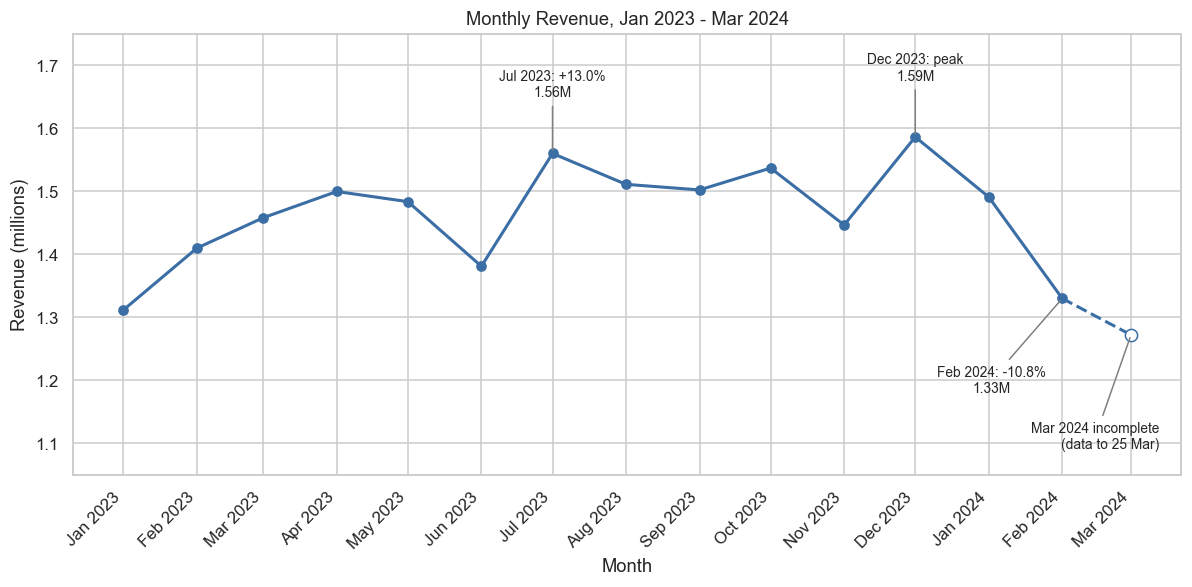

In [38]:
import matplotlib.dates as mdates

m = monthly.copy()
m.index = pd.to_datetime(m.index)          # '2023-01' -> a real date
rev = m["revenue"] / 1e6                   # revenue in millions

fig, ax = plt.subplots(figsize=(11, 5.5))

# full months: solid line with markers
ax.plot(m.index[:-1], rev.iloc[:-1], marker="o", color=BLUE, linewidth=2)
# last (incomplete) month: dashed segment and hollow marker
ax.plot(m.index[-2:], rev.iloc[-2:], linestyle="--", color=BLUE, linewidth=2)
ax.plot(m.index[-1], rev.iloc[-1], marker="o", markersize=8,
        markerfacecolor="white", markeredgecolor=BLUE, linestyle="none")

# annotations
def note(date, text, dy):
    d = pd.Timestamp(date)
    ax.annotate(text, xy=(d, rev[d]), xytext=(d, rev[d] + dy), ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="-", color="grey"))

note("2023-07-01", "Jul 2023: +13.0%\n1.56M", 0.09)
note("2023-12-01", "Dec 2023: peak\n1.59M", 0.09)
feb = pd.Timestamp("2024-02-01")
ax.annotate("Feb 2024: -10.8%\n1.33M", xy=(feb, rev[feb]),
            xytext=(feb - pd.Timedelta(days=30), 1.20), ha="center", va="center", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="grey"))

last = m.index[-1]
ax.annotate("Mar 2024 incomplete\n(data to 25 Mar)", xy=(last, rev.iloc[-1]),
            xytext=(last + pd.Timedelta(days=12), 1.11), ha="right", va="center", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="grey"))

ax.set_title("Monthly Revenue, Jan 2023 - Mar 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (millions)")
ax.set_ylim(1.05, 1.75)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "monthly-sales-trend.png"), dpi=150, bbox_inches="tight")
plt.show()

Insight: Monthly revenue moves between about 1.27 million and 1.59 million with no steady upward or downward trend. December 2023 is the highest month (1.59 million, up 9.7%), and July 2023 shows the largest rise (+13.0% to 1.56 million). June 2023 (-6.9%), November 2023 (-5.9%) and February 2024 (-10.8%) are the main dips. The February 2024 fall came with a 13.0% fall in orders (1,211 to 1,053), so changes in revenue follow order volume more than order size. March 2024 covers only 25 days, so its lower total should not be read as a decline. The data does not show what caused the peaks and dips.

Step 4: Pie Chart – Revenue Share by Payment Method
A pie chart suits this comparison because there are only five payment methods and the question is about each one's share of the whole. The largest segment is highlighted in orange and the other segments use shades of blue, in line with the colour scheme of the earlier charts.

Payment revenue adds up: True
Payment_Method
Credit Card         41.6
Debit Card          23.7
Digital Wallet      19.2
Bank Transfer       10.6
Cash on Delivery     4.8
Name: Total_Amount, dtype: float64


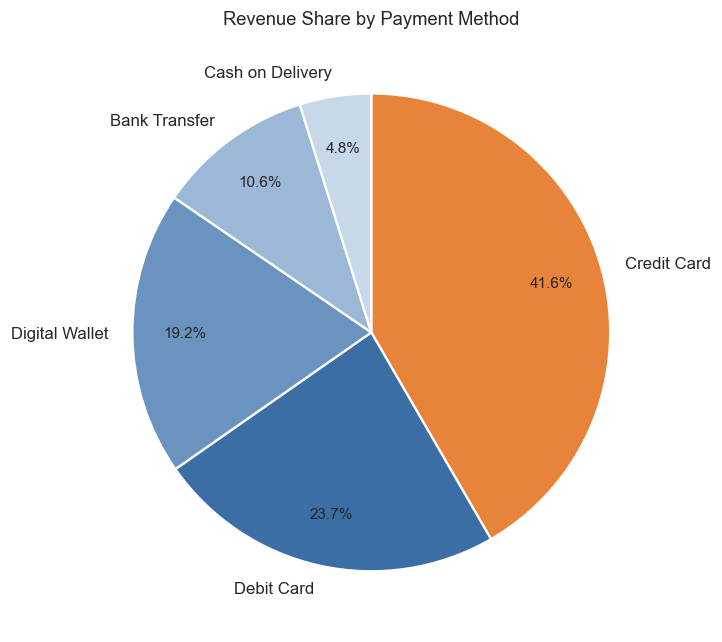

In [39]:
pay = df.groupby("Payment_Method")["Total_Amount"].sum().sort_values(ascending=False)

print("Payment revenue adds up:", round(pay.sum(), 2) == round(total_revenue, 2))
print((pay / pay.sum() * 100).round(1))

blues = ["#E8833A", "#3B6EA5", "#6A94BF", "#9BB8D6", "#C7D8E8"]   # largest in orange, then lighter blues

fig, ax = plt.subplots(figsize=(7.5, 6))
wedges, texts, autotexts = ax.pie(
    pay.values,
    labels=pay.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=blues,
    pctdistance=0.78,
    wedgeprops=dict(edgecolor="white", linewidth=1.5),
)
for t in autotexts:
    t.set_fontsize(10)

ax.set_title("Revenue Share by Payment Method")
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "revenue-by-payment-method.png"), dpi=150, bbox_inches="tight")
plt.show()

Insight: Credit cards bring the largest share of revenue (41.6%), followed by debit cards (23.7%) and digital wallets (19.2%). Together, credit and debit cards account for about 65% of revenue. Bank transfer (10.6%) and cash on delivery (4.8%) are the smallest. Each method's revenue share is close to its share of orders (for example, credit card 39.9% of orders and digital wallet 19.2%), so no payment method stands out for unusually large or small orders. The data does not show why customers choose each method.

Step 5: Dashboard Mockup
One page that combines the key numbers and visuals: four KPI cards at the top, the monthly revenue trend in the centre, revenue by category on the bottom left and orders by city (the region view) on the bottom right. It uses the same colour scheme as the earlier charts, with orange marking the largest bar.

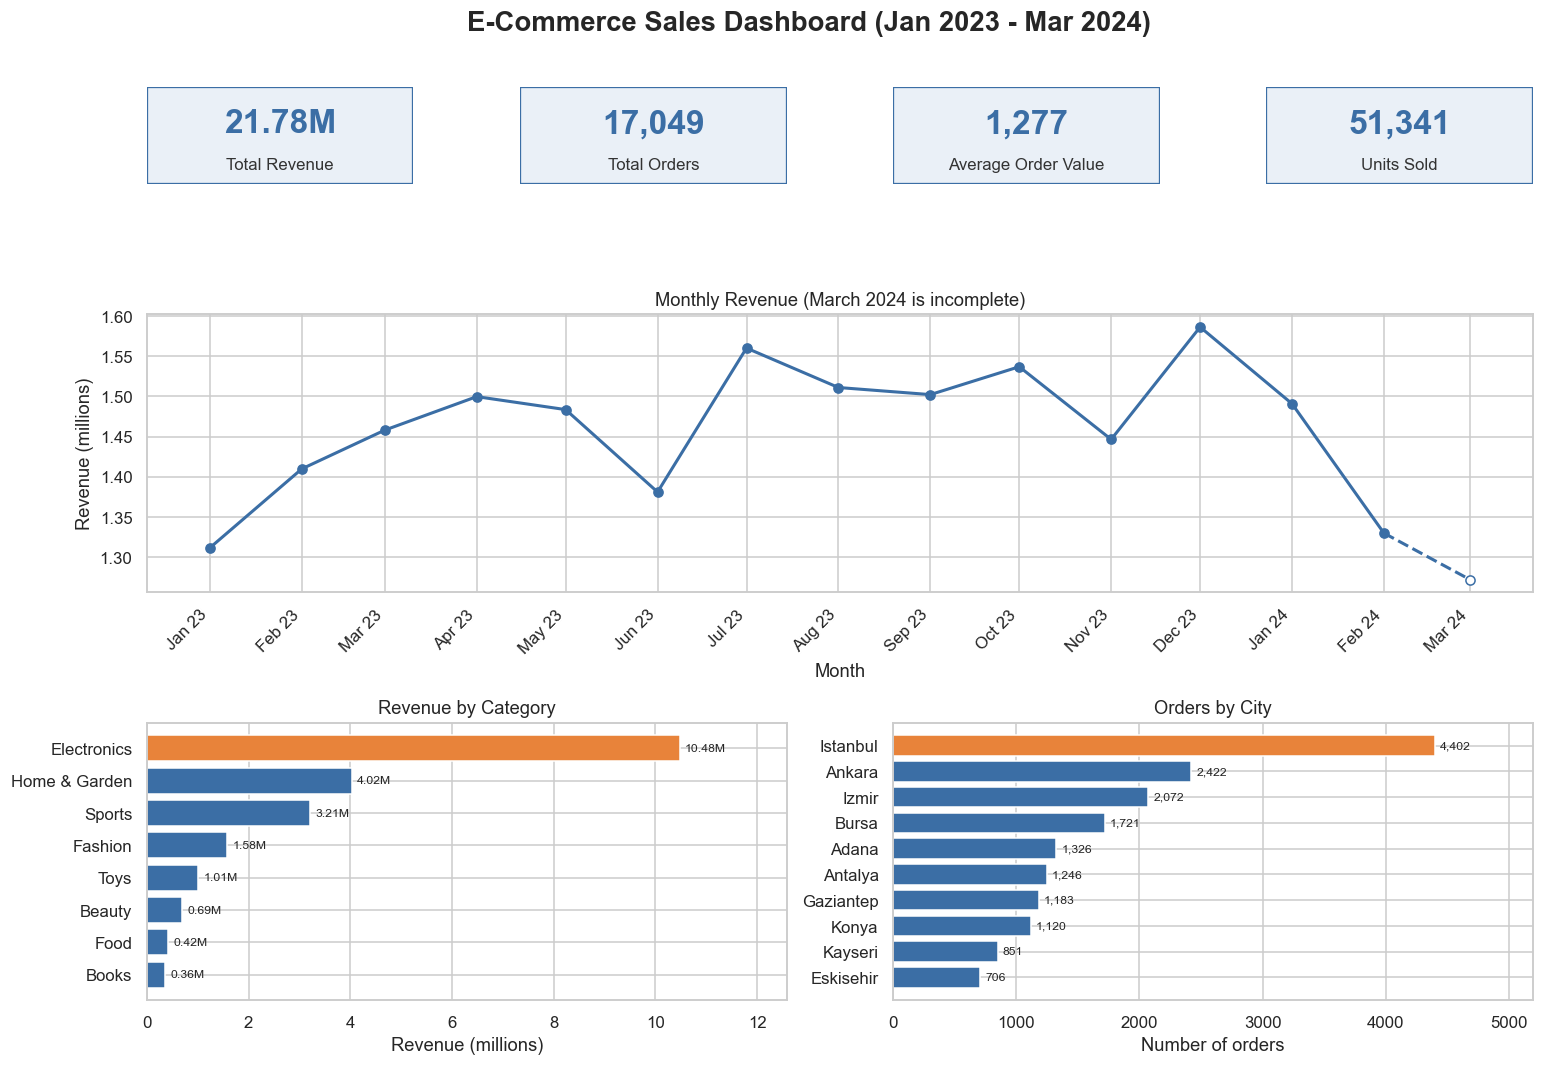

In [40]:
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(3, 4, height_ratios=[0.8, 2.3, 2.3], hspace=0.6, wspace=0.4,
                      top=0.90, bottom=0.07, left=0.07, right=0.97)
fig.suptitle("E-Commerce Sales Dashboard (Jan 2023 - Mar 2024)", fontsize=18, fontweight="bold", y=0.97)

# 1) KPI cards
kpis = [
    ("Total Revenue", f"{total_revenue/1e6:.2f}M"),
    ("Total Orders", f"{total_orders:,}"),
    ("Average Order Value", f"{aov:,.0f}"),
    ("Units Sold", f"{units_sold:,}"),
]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                               facecolor="#EAF0F7", edgecolor=BLUE, linewidth=1.5))
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=22, fontweight="bold",
            color=BLUE, transform=ax.transAxes)
    ax.text(0.5, 0.20, label, ha="center", va="center", fontsize=11, color="#333333",
            transform=ax.transAxes)

# 2) Trend chart (centre)
mm = monthly.copy()
mm.index = pd.to_datetime(mm.index)
r = mm["revenue"] / 1e6
ax = fig.add_subplot(gs[1, :])
ax.plot(mm.index[:-1], r.iloc[:-1], marker="o", color=BLUE, linewidth=2)
ax.plot(mm.index[-2:], r.iloc[-2:], linestyle="--", color=BLUE, linewidth=2)
ax.plot(mm.index[-1], r.iloc[-1], marker="o", markerfacecolor="white",
        markeredgecolor=BLUE, linestyle="none")
ax.set_title("Monthly Revenue (March 2024 is incomplete)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (millions)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# 3) Category comparison (bottom left)
cs = cat.sort_values("revenue", ascending=True)
cols = [HIGHLIGHT if c == cs.index[-1] else BLUE for c in cs.index]
ax = fig.add_subplot(gs[2, :2])
ax.barh(cs.index, cs["revenue"] / 1e6, color=cols)
for i, v in enumerate(cs["revenue"] / 1e6):
    ax.text(v + 0.1, i, f"{v:.2f}M", va="center", fontsize=8)
ax.set_title("Revenue by Category")
ax.set_xlabel("Revenue (millions)")
ax.set_xlim(0, cs["revenue"].max() / 1e6 * 1.2)

# 4) Region insight (bottom right)
co = city.sort_values("orders", ascending=True)
cols = [HIGHLIGHT if c == co.index[-1] else BLUE for c in co.index]
ax = fig.add_subplot(gs[2, 2:])
ax.barh(co.index, co["orders"], color=cols)
for i, v in enumerate(co["orders"]):
    ax.text(v + 40, i, f"{v:,}", va="center", fontsize=8)
ax.set_title("Orders by City")
ax.set_xlabel("Number of orders")
ax.set_xlim(0, co["orders"].max() * 1.18)

plt.savefig(os.path.join(dash_dir, "dashboard-mockup.png"), dpi=150, bbox_inches="tight")
plt.show()

Findings shown on the dashboard:
17,049 orders generated 21.78 million in revenue, with an average order value of about 1,277.
Monthly revenue stays between about 1.27 million and 1.59 million with no steady trend. March 2024 is incomplete.
Electronics brings 10.48 million (48.1% of revenue), more than Home & Garden and Sports combined.
Istanbul has the most orders (4,402, 25.8% of the total).

# Final Report

# Section 1

1. Title and Objective

E-Commerce Sales Analysis: Week 1 Report

Objective: Clean an e-commerce dataset of 17,049 orders, calculate core sales KPIs, analyse sales trends and customer behaviour, and communicate the results with charts and a dashboard.

Author: Manasi Humbe
Organization: WeIntern Pvt Ltd
Tools: Python, pandas, matplotlib, seaborn

# Section 2

2. Dataset Overview

The dataset contains 17,049 orders and 18 columns, placed by 5,000 customers in 10 Turkish cities between 1 January 2023 and 25 March 2024. Each order has a product category (8 categories), price, quantity, discount, total amount, payment method, device type, delivery time and customer rating. The data has two identifier columns, one date column, nine numeric columns, five categorical columns and one boolean column. The dataset has no product name and no order status column.

# Section 3

3. Cleaning Summary

The raw data was already in good condition. Every check was run and documented, and no rows were removed (17,049 of 17,049 kept).

Missing values: Nulls were checked in all 18 columns. Result: 0 (0.00%). Action: none needed.

Duplicates: Full-row duplicates and repeated Order IDs were checked. Result: 0. Action: none, no rows removed.

Repeat customers: 4,108 of the 5,000 customers placed more than one order. Action: kept, because these are valid repeat purchases.

Data types: Date was stored as text. Action: converted to datetime.

ID format: Order_ID and Customer_ID patterns were checked. Result: all valid. Action: none needed.

Validation: 11 business rules were tested. Result: 0 violations. Action: none needed.

Categories: Spaces and spelling variants were checked. Result: none found. Action: whitespace trimmed.

Outliers: The IQR rule on Total_Amount flagged 1,943 orders (11.4%). Action: kept, because they are valid high-value orders.

Derived columns: Order_Base, Order_Month and Delivery_Status were added and used in the analysis.

# Section 4

4. KPI Summary

Total Revenue: 21,779,052.59
Total Orders: 17,049
Average Order Value: 1,277.44
Median Order Value: 455.85
Total Units Sold: 51,341
Top Category (revenue): Electronics
Top Category (units): Sports
Best Product (revenue): Electronics (Product_Category is used, because the data has no product name)

The average order value is about 2.8 times the median, because a few very large orders pull the average up.

# Section 5

5. Trend Analysis

Monthly: Revenue stays between about 1.27 million and 1.59 million with no steady upward or downward trend. July 2023 shows the largest rise (+13.0%), December 2023 is the highest month (1.59 million) and February 2024 shows the largest fall (-10.8%). Changes in revenue follow the number of orders more than order size. March 2024 is incomplete, because the data ends on 25 March.

Category: Electronics brings 48.1% of revenue from about 12% of orders. Order counts are similar across categories, so the revenue differences come from price.

City: Istanbul brings 25.9% of revenue, in line with its share of orders. The top three cities bring about 52% of revenue, and average order value is similar across cities.

Delivery: Standard deliveries are the largest group (48.2% of orders). Ratings are almost identical across Fast, Standard and Slow deliveries (3.91, 3.90 and 3.89).

# Section 6

6. Customer Insights

Returning customers account for 88.2% of orders and 88.1% of revenue, and their average order value (1,276.06) is almost the same as first-time customers (1,287.73). Of the 5,000 customers, 4,108 ordered more than once, and together they bring 95.1% of revenue. Revenue is moderately concentrated: the top 10% of customers bring 38.8% of revenue. Revenue therefore depends on customers who buy repeatedly.

# Section 7

7. Visualization Section

The charts below are saved in the outputs folder.

Revenue by category (bar chart): Electronics brings 10.48 million (48.1%), more than Home & Garden and Sports combined.

Orders by city (bar chart): Istanbul has the most orders (4,402, 25.8%).

Orders by delivery status (bar chart): Standard deliveries are the largest group with 8,221 orders (48.2%).

Monthly revenue (line chart): Revenue is stable, with peaks in July and December 2023.

Revenue share by payment method (pie chart): Credit cards bring 41.6% of revenue and debit cards 23.7%.

Dashboard mockup: KPI cards, the monthly trend, revenue by category and orders by city on one page.

# Section 8

8. Key Findings
   
1.The 17,049 orders generated 21.78 million in revenue and 51,341 units. The average order value (1,277.44) is about 2.8 times the median (455.85).
2.Electronics generates 48.1% of revenue from about 12% of orders, and Electronics, Home & Garden and Sports together bring about 81%.
3.Sports has the most orders (2,248) and units (6,856) but ranks third in revenue. Revenue differences come from price, not demand.
4.Monthly revenue stays between 1.27 million and 1.59 million with no steady trend, and changes follow order volume more than order size.
5.Istanbul, Ankara and Izmir bring about 52% of revenue, and average order value is similar across cities.
6.Delivery speed shows no link to satisfaction: ratings are 3.91, 3.90 and 3.89.
7.Returning customers account for 88.1% of revenue.
8.The top 10% of customers bring 38.8% of revenue, and customers who ordered more than once bring 95.1%.

# Section 9

9. Recommendations
    
1. Observation: Electronics brings 48.1% of revenue from about 12% of orders.
Recommendation: Keep Electronics well stocked and its delivery and service reliable, because total revenue depends heavily on it.
2. Observation: Sports has the most orders (2,248) and units (6,856) but ranks third in revenue.
Recommendation: Look for ways to raise order value in Sports, for example bundles or add-on items.
3. Observation: Beauty, Food and Books together bring under 7% of revenue.
Recommendation: Review pricing and promotion for these categories, or decide whether they serve a different purpose such as attracting customers.
4. Observation: Returning customers account for 88.1% of revenue, and customers who ordered more than once account for 95.1%.
Recommendation: Put effort into retention, such as loyalty offers or reminders, because repeat buyers protect most of the revenue.
5. Observation: The top 10% of customers bring 38.8% of revenue.
Recommendation: Identify these customers and consider a dedicated programme for them.
6. Observation: Monthly revenue follows the number of orders more than order size, with peaks in July and December 2023.
Recommendation: Plan stock and campaigns around the busiest months, and investigate what drove those peaks before repeating them.
7. Observation: Istanbul, Ankara and Izmir bring about 52% of revenue, and Adana has the lowest average order value (1,140.51).
Recommendation: Prioritise service capacity in the top three cities, and look at what limits order value in Adana.
8. Observation: Ratings are almost the same across Fast, Standard and Slow deliveries (3.91, 3.90 and 3.89).
Recommendation: Collect data on repeat purchases by delivery speed before investing in faster delivery, since ratings alone show no link.

# Section 10

10. Limitations and Assumptions

Assumptions
Every row is treated as a completed sale, because the dataset has no cancelled or returned status.
Revenue means Total_Amount, the final amount paid after discount.
The dataset has no product name, so Product_Category stands in for "product" and for "best product".
Delivery_Status (Fast: 3 days or fewer, Standard: 4 to 7, Slow: 8 or more) was derived from Delivery_Time_Days. The cut-offs are my own choice, and different cut-offs would change the group sizes.

Limitations
The data ends on 25 March 2024, so March 2024 is an incomplete month and its lower revenue should not be read as a decline.
The data covers only 15 months, so seasonal patterns cannot be confirmed. The July and December peaks occurred once each.
The dataset has no cost or profit information, so the analysis describes revenue, not profit.
Returning customers are measured in two ways: by the Is_Returning_Customer flag on each order (88.1% of revenue) and by the number of orders per Customer_ID (95.1% of revenue for customers with more than one order). The two figures use different definitions and are not directly comparable.
The analysis shows patterns, not causes. For example, it shows that ratings are similar across delivery speeds, but it cannot show whether delivery speed affects repeat buying.
No data was removed in cleaning, so all 1,943 high-value orders (11.4%) remain in the results and raise the average order value above the median.